# AL Snapshot Plots

Compares 1D active-learning rollouts with one method per row and fixed snapshot rounds per column.

Default setup:
- `GP variance reduction`
- `GP weighted variance reduction`
- `Ours (TabICL policy)`
- benchmark task `sine_gaussian_bumps`

To switch to GP-prior examples later, change `TASK_KIND` to `"gp_regression"` and set `EPISODE_SEED` to something like `"test0"` in the config cell.


In [120]:
from __future__ import annotations

from pathlib import Path
from types import SimpleNamespace
import os
import sys
import warnings

os.environ.setdefault("XDG_CACHE_HOME", "/tmp/polar-xdg-cache")
os.environ.setdefault("MPLCONFIGDIR", "/tmp/polar-matplotlib-cache")

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display
from matplotlib.ticker import FormatStrFormatter
from omegaconf import OmegaConf

%load_ext autoreload
%autoreload 2


def find_repo_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / ".git").exists() and (candidate / "src").exists():
            return candidate
    raise RuntimeError("Could not find repo root from the current notebook directory.")


REPO_ROOT = find_repo_root(Path.cwd().resolve())
SRC_ROOT = REPO_ROOT / "src"
if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))

from polar.evaluation.al import (  # noqa: E402
    episode_raw_x_to_model,
    rollout_policy_probe_episode,
    rollout_surrogate_probe_episode,
)
from polar.trainers import score_policy_head  # noqa: E402
from polar.tasks import create_al_task  # noqa: E402
from polar.utils.al_acquisitions import (  # noqa: E402
    ALAcquisitionInputs,
    compute_al_acquisition_scores,
)
from polar.utils.plotting import (  # noqa: E402
    PAPER_COLORS,
    apply_style,
    draw_policy_probe_score_axis,
    draw_policy_probe_snapshot_axis,
)
from polar.utils.policy_loading import load_policy_checkpoint  # noqa: E402
from polar.utils.surrogates import GPyTorchSurrogate  # noqa: E402




The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [121]:
SEED = 1
DEVICE = "cpu"

TASK_KIND = "benchmark_functions"  # "benchmark_functions" | "gp_regression"
DATASET_ID = "sine_gaussian_bumps"  # ignored for gp_regression
EPISODE_SEED = "episode0"  # benchmark_functions: episode0/... | gp_regression: test0/...
N_CONTEXT_INIT = 2
N_QUERY = 500
N_TARGET = 100
PLOT_GRID_SIZE = 400
NUM_ACQUISITIONS = 30
SNAPSHOT_ROUNDS = (10, 15, 20, 25, 30)  # 1-based rounds shown as columns

REPORT_TARGET_WEIGHTING = "exp_y"
REPORT_TARGET_WEIGHT_BETA = 2.0
CI_STD = 1.96

POLAR_CHECKPOINT = REPO_ROOT / "notebooks/final_results/loss_driven_al/polar/checkpoint.pt"

METHOD_SPECS = [
    {
        "name": "gp_variance_reduction",
        "label": "GP-VR",
        "kind": "surrogate",
        "backend": "gp",
        "acquisition_name": "variance_reduction",
    },
    {
        "name": "gp_weighted_variance_reduction",
        "label": "$\\text{GP-VR}_w$",
        "kind": "surrogate",
        "backend": "gp",
        "acquisition_name": "weighted_variance_reduction",
    },
    {
        "name": "polar",
        "label": "POLAR",
        "kind": "policy",
        "backend": "tabicl",
        "policy_checkpoint_path": POLAR_CHECKPOINT,
    },
]

PLOT_STYLE = {
    "base_font_size": 14.5,
    "width_per_col": 3.8,
    "height_per_method": 4.35,
    "sharey": True,
    "upper_height_ratio": 3.0,
    "lower_height_ratio": 1.15,
    "cell_hspace": 0.05,
    "figure_wspace": 0.34,
    "figure_hspace": 0.24,
    "band_alpha": 0.26,
    "queried_size": 30.0,
    "queried_color": "#111111",
    "latest_color": "#CC3311",
    "latest_linewidth": 1.6,
    "legend_ncol": 4,
    "metrics_fontsize_offset": 3.0,
    "score_linewidth": 1.7,
    "score_fill_alpha": 0.10,
}


In [122]:
def load_yaml_cfg(relative_path: str):
    return OmegaConf.load(REPO_ROOT / relative_path)


def build_task_cfg(task_kind: str, *, dataset_id: str | None = None):
    task_kind = str(task_kind).strip().lower()
    if task_kind == "benchmark_functions":
        if dataset_id is None:
            raise ValueError("dataset_id is required for benchmark_functions.")
        task_cfg = load_yaml_cfg("config/task/benchmark_functions.yaml")
        task_cfg.benchmarks = [str(dataset_id)]
        task_cfg.split = "test"
    elif task_kind == "gp_regression":
        task_cfg = load_yaml_cfg("config/task/gp_regression.yaml")
        task_cfg.split = "test"
        task_cfg.plot_grid_size = int(PLOT_GRID_SIZE)
    else:
        raise ValueError(f"Unsupported TASK_KIND: {task_kind}")

    task_cfg.n_context_init = int(N_CONTEXT_INIT)
    task_cfg.n_query = int(N_QUERY)
    task_cfg.n_target = int(N_TARGET)
    return task_cfg


def attach_benchmark_plot_bundle(episode, plot_bundle: dict[str, object]):
    raw_plot_x = torch.as_tensor(plot_bundle["raw_plot_x"], dtype=torch.float32)
    raw_plot_y_true = torch.as_tensor(plot_bundle["raw_plot_y_true"], dtype=torch.float32)
    plot_x = episode_raw_x_to_model(episode, raw_plot_x)

    y_mean = torch.as_tensor(getattr(episode, "y_mean", 0.0), dtype=torch.float32)
    y_std = torch.as_tensor(getattr(episode, "y_std", 1.0), dtype=torch.float32)
    plot_y_true = (raw_plot_y_true - y_mean) / y_std

    payload = dict(getattr(episode, "__dict__", {}))
    payload.update(
        {
            "plot_x": plot_x,
            "plot_y_true": plot_y_true,
            "raw_plot_x": raw_plot_x,
            "raw_plot_y_true": raw_plot_y_true,
        }
    )
    return SimpleNamespace(**payload)


def build_episode(task, task_cfg, *, task_kind: str, episode_seed: str, dataset_id: str | None = None):
    task_kind = str(task_kind).strip().lower()
    if task_kind == "benchmark_functions":
        if dataset_id is None:
            raise ValueError("dataset_id is required for benchmark_functions.")
        episode = task.build_test_episode(
            dataset_id=str(dataset_id),
            seed=str(episode_seed),
            n_context=int(task_cfg.n_context_init),
            query_pool_size=int(task_cfg.n_query),
            n_target=int(task_cfg.n_target),
        )
        plot_bundle = task.plot_bundle(
            str(dataset_id),
            resolution_1d=int(PLOT_GRID_SIZE),
        )
        return attach_benchmark_plot_bundle(episode, plot_bundle)

    if task_kind == "gp_regression":
        return task.build_test_episode(
            seed=str(episode_seed),
            n_context=int(task_cfg.n_context_init),
            query_pool_size=int(task_cfg.n_query),
            n_target=int(task_cfg.n_target),
        )

    raise ValueError(f"Unsupported TASK_KIND: {task_kind}")


def build_gp_surrogate(*, device: str):
    model_cfg = load_yaml_cfg("config/model/gp.yaml")
    return GPyTorchSurrogate(
        kernel=str(model_cfg.kernel),
        training_steps=int(model_cfg.training_steps),
        learning_rate=float(model_cfg.learning_rate),
        initial_noise=float(model_cfg.initial_noise),
        device=str(device),
    )


_POLICY_CACHE: dict[str, object] = {}


def load_policy_for_method(method_spec: dict[str, object], *, device: str):
    cache_key = str(method_spec["name"])
    if cache_key in _POLICY_CACHE:
        return _POLICY_CACHE[cache_key]

    backend = str(method_spec["backend"])
    model_cfg = load_yaml_cfg(f"config/model/{backend}.yaml")
    policy_cfg = OmegaConf.create({})
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=FutureWarning)
        loaded = load_policy_checkpoint(
            backend=backend,
            model_cfg=model_cfg,
            policy_cfg=policy_cfg,
            device=str(device),
            checkpoints_root=str(REPO_ROOT / "checkpoints"),
            policy_checkpoint_path=Path(method_spec["policy_checkpoint_path"]),
        )
    _POLICY_CACHE[cache_key] = loaded
    return loaded


def filter_snapshots(round_snapshots, snapshot_rounds):
    snapshot_by_round = {
        int(snapshot["round"]) + 1: snapshot
        for snapshot in round_snapshots
    }
    return [
        snapshot_by_round[int(round_number)]
        for round_number in snapshot_rounds
        if int(round_number) in snapshot_by_round
    ]


def current_context_from_snapshot(snapshot):
    context_x = snapshot["context_x"].detach().cpu()
    context_y = snapshot["context_y"].detach().cpu()
    return context_x, context_y


def attach_dense_score_curve(snapshot, *, method_spec: dict[str, object], episode, surrogate=None, loaded=None):
    dense_raw_x = snapshot.get("raw_plot_x")
    if dense_raw_x is None:
        return snapshot

    dense_raw_x = torch.as_tensor(dense_raw_x, dtype=torch.float32).detach().cpu()
    dense_model_x = episode_raw_x_to_model(episode, dense_raw_x)
    context_x, context_y = current_context_from_snapshot(snapshot)
    target_x = snapshot["target_x"].detach().cpu()

    if str(method_spec["kind"]) == "surrogate":
        if surrogate is None:
            raise ValueError("surrogate is required for dense surrogate score curves.")
        surrogate.fit(context_x, context_y)
        acquisition_name = str(method_spec["acquisition_name"])
        if acquisition_name in {"variance_reduction", "weighted_variance_reduction"} and hasattr(surrogate, "predict_query_target_joint"):
            joint_pred = surrogate.predict_query_target_joint(dense_model_x, target_x)
            score_inputs = ALAcquisitionInputs(
                backend=str(surrogate.backend_name),
                query_x=dense_model_x,
                query_mean=joint_pred.query_mean,
                query_variance=joint_pred.query_variance,
                target_x=target_x,
                target_mean=joint_pred.target_mean,
                target_variance=joint_pred.target_variance,
                target_query_covariance=joint_pred.target_query_covariance,
                target_weighting=str(REPORT_TARGET_WEIGHTING),
                target_weight_beta=float(REPORT_TARGET_WEIGHT_BETA),
            )
        else:
            union_pred = surrogate.predict(torch.cat([dense_model_x, target_x], dim=0))
            n_dense = int(dense_model_x.shape[0])
            score_inputs = ALAcquisitionInputs(
                backend=str(surrogate.backend_name),
                query_x=dense_model_x,
                query_mean=union_pred.mean[:n_dense],
                query_variance=union_pred.variance[:n_dense],
                target_x=target_x,
                target_mean=union_pred.mean[n_dense:],
                target_variance=union_pred.variance[n_dense:],
                target_weighting=str(REPORT_TARGET_WEIGHTING),
                target_weight_beta=float(REPORT_TARGET_WEIGHT_BETA),
            )
        dense_scores = compute_al_acquisition_scores(name=acquisition_name, inputs=score_inputs)
        snapshot["score_curve_values"] = dense_scores.detach().cpu()
        snapshot["score_curve_raw_x"] = dense_raw_x
        snapshot["selected_score_value"] = None
        return snapshot

    if str(method_spec["kind"]) == "policy":
        if loaded is None:
            raise ValueError("loaded policy is required for dense policy score curves.")
        context_x_batch = context_x.unsqueeze(0).to(loaded.backbone.device).float()
        context_y_batch = context_y.unsqueeze(0).to(loaded.backbone.device).float()
        target_x_batch = target_x.unsqueeze(0).to(loaded.backbone.device).float()
        dense_x_batch = dense_model_x.unsqueeze(0).to(loaded.backbone.device).float()
        with torch.inference_mode():
            context_state = loaded.backbone.encode_context(context_x_batch, context_y_batch)
            outputs = loaded.backbone.forward_with_embeddings(
                torch.cat([dense_x_batch, target_x_batch], dim=1),
                context_state,
            )
            union_embeddings = outputs["test_embeddings"]
            if union_embeddings is None:
                raise KeyError("forward_with_embeddings must return test_embeddings.")
            n_dense = int(dense_x_batch.shape[1])
            dense_embeddings = union_embeddings[:, :n_dense]
            target_embeddings = union_embeddings[:, n_dense:]
            dense_scores = score_policy_head(
                loaded.policy_head,
                query_embeddings=dense_embeddings,
                target_embeddings=target_embeddings,
            )
            dense_probs = torch.softmax(dense_scores, dim=1)[0].detach().cpu()
        snapshot["score_curve_values"] = dense_probs
        snapshot["score_curve_raw_x"] = dense_raw_x
        snapshot["selected_score_value"] = None
        return snapshot

    return snapshot


def run_method_on_episode(method_spec: dict[str, object], episode):
    kind = str(method_spec["kind"])
    if kind == "surrogate":
        surrogate = build_gp_surrogate(device=DEVICE)
        with torch.enable_grad():
            round_metrics, round_snapshots = rollout_surrogate_probe_episode(
                episode=episode,
                surrogate=surrogate,
                acquisition_name=str(method_spec["acquisition_name"]),
                num_acquisitions=int(NUM_ACQUISITIONS),
                collect_snapshots=True,
                snapshot_round_stride=1,
                policy_target_weighting=str(REPORT_TARGET_WEIGHTING),
                policy_target_weight_beta=float(REPORT_TARGET_WEIGHT_BETA),
            )
        selected_snapshots = [
            attach_dense_score_curve(snapshot, method_spec=method_spec, episode=episode, surrogate=surrogate)
            for snapshot in filter_snapshots(round_snapshots, SNAPSHOT_ROUNDS)
        ]
    elif kind == "policy":
        loaded = load_policy_for_method(method_spec, device=DEVICE)
        with torch.inference_mode():
            round_metrics, round_snapshots = rollout_policy_probe_episode(
                episode=episode,
                backbone=loaded.backbone,
                policy_head=loaded.policy_head,
                num_acquisitions=int(NUM_ACQUISITIONS),
                selection="argmax",
                collect_snapshots=True,
                snapshot_round_stride=1,
                policy_target_weighting=str(REPORT_TARGET_WEIGHTING),
                policy_target_weight_beta=float(REPORT_TARGET_WEIGHT_BETA),
            )
        selected_snapshots = [
            attach_dense_score_curve(snapshot, method_spec=method_spec, episode=episode, loaded=loaded)
            for snapshot in filter_snapshots(round_snapshots, SNAPSHOT_ROUNDS)
        ]
    else:
        raise ValueError(f"Unsupported method kind: {kind}")

    return {
        **method_spec,
        "round_metrics": round_metrics,
        "round_snapshots": round_snapshots,
        "selected_snapshots": selected_snapshots,
    }


def summarize_method_run(result: dict[str, object]) -> dict[str, object]:
    round_metrics = result["round_metrics"]
    selected_snapshots = result["selected_snapshots"]
    row = {
        "method": result["label"],
        "num_rounds": len(round_metrics),
        "num_selected_snapshots": len(selected_snapshots),
        "final_rmse": float(round_metrics[-1]["target_rmse"]),
        "final_wrmse": float(round_metrics[-1]["weighted_target_rmse"]),
    }
    for snapshot in selected_snapshots:
        round_number = int(snapshot["round"]) + 1
        row[f"r{round_number}_rmse"] = float(snapshot["target_rmse"])
        row[f"r{round_number}_wrmse"] = float(snapshot["weighted_target_rmse"])
    return row


In [123]:
torch.manual_seed(int(SEED))

task_cfg = build_task_cfg(TASK_KIND, dataset_id=DATASET_ID)
task = create_al_task(task_cfg, seed=int(SEED))
episode = build_episode(
    task,
    task_cfg,
    task_kind=TASK_KIND,
    episode_seed=EPISODE_SEED,
    dataset_id=DATASET_ID,
)

episode_info = {
    "task_kind": TASK_KIND,
    "dataset_id": getattr(episode, "dataset_id", "gp_prior"),
    "episode_seed": EPISODE_SEED,
    "context_size": int(episode.context_x.shape[0]),
    "query_size": int(episode.query_x.shape[0]),
    "target_size": int(episode.target_x.shape[0]),
    "has_raw_plot": hasattr(episode, "raw_plot_x"),
}
display(pd.DataFrame([episode_info]))


,task_kind,dataset_id,episode_seed,context_size,query_size,target_size,has_raw_plot
0,benchmark_functions,sine_gaussian_bumps,episode0,2,500,100,True


In [124]:
results = [run_method_on_episode(method_spec, episode) for method_spec in METHOD_SPECS]
summary_df = pd.DataFrame([summarize_method_run(result) for result in results])
display(summary_df)


,method,num_rounds,num_selected_snapshots,final_rmse,final_wrmse,r10_rmse,r10_wrmse,r15_rmse,r15_wrmse,r20_rmse,r20_wrmse,r25_rmse,r25_wrmse,r30_rmse,r30_wrmse
0,GP-VR,30,5,0.042134,0.293353,0.503115,3.178415,0.483436,3.230395,0.134036,0.149013,0.100731,0.203881,0.042134,0.293353
1,$\text{GP-VR}_w$,30,5,0.192989,0.060933,0.399926,0.171722,0.353161,0.056744,0.229242,0.060133,0.184040,0.054132,0.192989,0.060933
2,Ours,30,5,0.071959,0.253257,0.670416,3.374438,0.572004,3.093077,0.573545,2.991077,0.125706,0.212760,0.071959,0.253257


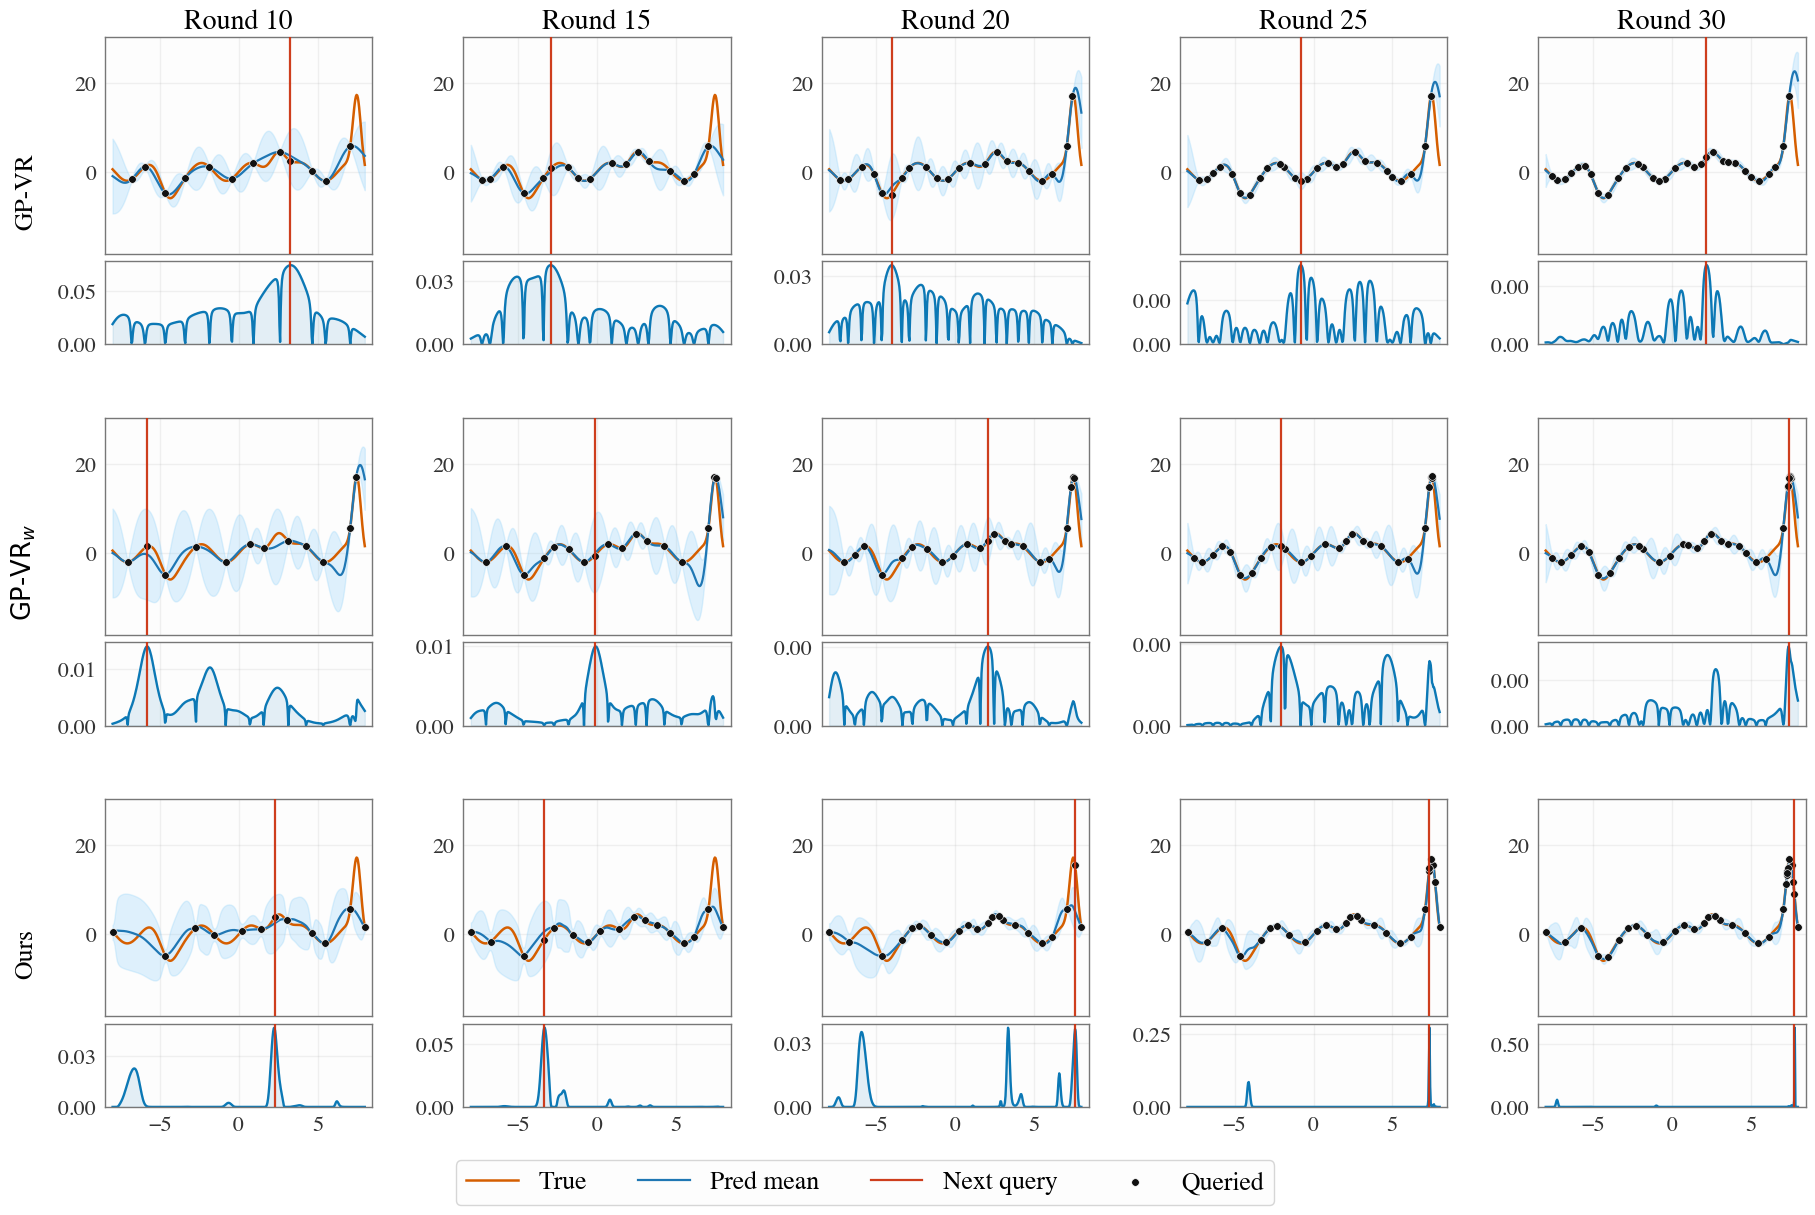

In [132]:
def plot_method_snapshot_matrix(
    results,
    *,
    snapshot_rounds,
    ci_std: float,
    plot_style: dict[str, float | bool | str],
    dataset_label: str | None = None,
):
    if not results:
        raise ValueError("results must be non-empty.")

    snapshot_pool = [
        snapshot
        for result in results
        for snapshot in result["selected_snapshots"]
    ]
    if not snapshot_pool:
        raise ValueError("No selected snapshots were collected.")

    apply_style(use_tex=False, base_font_size=float(plot_style["base_font_size"]))

    n_rows = len(results)
    n_cols = len(snapshot_rounds)
    fig = plt.figure(
        figsize=(
            float(plot_style["width_per_col"]) * n_cols,
            float(plot_style["height_per_method"]) * n_rows,
        )
    )
    outer_grid = fig.add_gridspec(
        n_rows,
        n_cols,
        wspace=float(plot_style.get("figure_wspace", 0.14)),
        hspace=float(plot_style.get("figure_hspace", 0.24)),
    )

    upper_axis_style = {
        "band_alpha": float(plot_style.get("band_alpha", 0.35)),
        "queried_size": float(plot_style.get("queried_size", 24.0)),
        "queried_color": str(plot_style.get("queried_color", "#111111")),
        "queried_edgecolor": "white",
        "queried_linewidths": 0.45,
        "latest_color": str(plot_style.get("latest_color", "#CC3311")),
        "latest_linewidths": float(plot_style.get("latest_linewidth", 1.6)),
        "grid_alpha": 0.18,
    }
    score_axis_style = {
        "score_color": str(plot_style.get("score_color", PAPER_COLORS[0])),
        "score_linewidth": float(plot_style.get("score_linewidth", 1.7)),
        "score_fill_alpha": float(plot_style.get("score_fill_alpha", 0.10)),
        "latest_color": str(plot_style.get("latest_color", "#CC3311")),
        "latest_linewidth": float(plot_style.get("latest_linewidth", 1.6)),
        "grid_alpha": 0.18,
    }

    base_font_size = float(plot_style["base_font_size"])
    tick_labelsize = base_font_size + 1.5
    upper_height_ratio = float(plot_style.get("upper_height_ratio", 3.0))
    lower_height_ratio = float(plot_style.get("lower_height_ratio", 1.15))
    cell_hspace = float(plot_style.get("cell_hspace", 0.05))

    upper_x_min = float("inf")
    upper_x_max = float("-inf")
    upper_y_min = float("inf")
    upper_y_max = float("-inf")
    for snapshot in snapshot_pool:
        x_line = (
            snapshot["raw_plot_x"].squeeze(-1).detach().cpu()
            if "raw_plot_x" in snapshot
            else snapshot["context_x"].squeeze(-1).detach().cpu()
        )
        y_true = (
            snapshot["raw_plot_y_true"].detach().cpu()
            if "raw_plot_y_true" in snapshot
            else snapshot["true_y"].detach().cpu()
        )
        pred_mean = (
            snapshot["pred_mean_raw"].detach().cpu()
            if "pred_mean_raw" in snapshot
            else snapshot["pred_mean"].detach().cpu()
        )
        pred_std = (
            snapshot["pred_std_raw"].detach().cpu()
            if "pred_std_raw" in snapshot
            else snapshot["pred_std"].detach().cpu()
        )
        queried_y_parts = [
            (
                snapshot["raw_context_y"].detach().cpu()
                if "raw_context_y" in snapshot
                else snapshot["context_y"].detach().cpu()
            )
        ]
        acquired_y = snapshot.get("acquired_raw_y")
        if acquired_y is not None and acquired_y.numel() > 0:
            queried_y_parts.append(acquired_y.detach().cpu())

        lower_band = pred_mean - float(ci_std) * pred_std
        upper_band = pred_mean + float(ci_std) * pred_std
        y_all = torch.cat(
            [
                y_true.reshape(-1),
                pred_mean.reshape(-1),
                lower_band.reshape(-1),
                upper_band.reshape(-1),
                *[part.reshape(-1) for part in queried_y_parts if part.numel() > 0],
            ],
            dim=0,
        )

        upper_x_min = min(upper_x_min, float(x_line.min().item()))
        upper_x_max = max(upper_x_max, float(x_line.max().item()))
        upper_y_min = min(upper_y_min, float(y_all.min().item()))
        upper_y_max = max(upper_y_max, float(y_all.max().item()))

    x_pad = 0.03 * max(upper_x_max - upper_x_min, 1e-6)
    y_pad = 0.08 * max(upper_y_max - upper_y_min, 1e-6)
    upper_xlim = (upper_x_min - x_pad, upper_x_max + x_pad)
    upper_ylim = (upper_y_min - y_pad, upper_y_max + y_pad)

    panel_axes: list[list[tuple[object, object]]] = []
    row_label_specs: list[tuple[str, object, object]] = []
    legend_handles: list[object] = []
    legend_labels: list[str] = []
    legend_order = ["True", "Pred mean", "Next query", "Queried"]

    for row_idx, result in enumerate(results):
        row_axes: list[tuple[object, object]] = []
        snapshot_by_round = {
            int(snapshot["round"]) + 1: snapshot
            for snapshot in result["selected_snapshots"]
        }
        for col_idx, round_number in enumerate(snapshot_rounds):
            cell_grid = outer_grid[row_idx, col_idx].subgridspec(
                2,
                1,
                height_ratios=[upper_height_ratio, lower_height_ratio],
                hspace=cell_hspace,
            )
            ax_upper = fig.add_subplot(cell_grid[0, 0])
            ax_lower = fig.add_subplot(cell_grid[1, 0], sharex=ax_upper)
            row_axes.append((ax_upper, ax_lower))

            snapshot = snapshot_by_round.get(int(round_number))
            if snapshot is None:
                ax_upper.axis("off")
                ax_lower.axis("off")
                continue

            draw_policy_probe_snapshot_axis(
                ax_upper,
                snapshot=snapshot,
                ci_std=float(ci_std),
                title=f"Round {round_number}" if row_idx == 0 else None,
                style=upper_axis_style,
                show_target=False,
                combine_context_and_acquired=True,
                latest_query_style="vline",
            )
            draw_policy_probe_score_axis(
                ax_lower,
                snapshot=snapshot,
                style=score_axis_style,
            )

            ax_upper.set_xlim(*upper_xlim)
            ax_lower.set_xlim(*upper_xlim)
            if bool(plot_style.get("sharey", True)):
                ax_upper.set_ylim(*upper_ylim)

            ax_upper.tick_params(axis="both", labelsize=tick_labelsize)
            ax_lower.tick_params(axis="both", labelsize=tick_labelsize)
            ax_upper.tick_params(labelbottom=False)
            if row_idx != n_rows - 1:
                ax_lower.tick_params(labelbottom=False)
            ax_lower.set_ylabel("")
            ax_lower.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))

            # ax_upper.text(
            #     0.02,
            #     0.97,
            #     (
            #         f"RMSE={float(snapshot['target_rmse']):.3f}\n"
            #         f"wRMSE={float(snapshot['weighted_target_rmse']):.3f}"
            #     ),
            #     transform=ax_upper.transAxes,
            #     va="top",
            #     ha="left",
            #     fontsize=metrics_fontsize,
            #     bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "none", "pad": 2.0},
            # )
            if col_idx == 0:
                row_label_specs.append((str(result["label"]), ax_upper, ax_lower))

            handles, labels = ax_upper.get_legend_handles_labels()
            for handle, label in zip(handles, labels, strict=False):
                display_label = "Next query" if label == "Latest query" else label
                if display_label not in legend_order or display_label in legend_labels:
                    continue
                legend_handles.append(handle)
                legend_labels.append(display_label)

        panel_axes.append(row_axes)

    if legend_handles:
        ordered_pairs = [
            (legend_handles[legend_labels.index(label)], label)
            for label in legend_order
            if label in legend_labels
        ]
        fig.legend(
            [handle for handle, _ in ordered_pairs],
            [label for _, label in ordered_pairs],
            loc="lower center",
            ncol=int(plot_style.get("legend_ncol", 4)),
            bbox_to_anchor=(0.5, 0.015),
            fontsize=base_font_size+4,
        )

    # fig.supxlabel("x", y=0.075, fontsize=base_font_size)
    # fig.suptitle(
    #     f"{dataset_label or getattr(episode, 'dataset_id', TASK_KIND)} | seed={EPISODE_SEED}",
    #     y=0.985,
    # )
    fig.subplots_adjust(left=0.10, right=0.995, bottom=0.1, top=0.92)
    for label_text, ax_upper, ax_lower in row_label_specs:
        upper_bbox = ax_upper.get_position()
        lower_bbox = ax_lower.get_position()
        row_y_center = 0.5 * (upper_bbox.y1 + lower_bbox.y0)
        fig.text(
            upper_bbox.x0 - 0.035,
            row_y_center,
            label_text,
            rotation=90,
            va="center",
            ha="right",
            fontsize=base_font_size + 4,
        )
    return fig, panel_axes


fig, panel_axes = plot_method_snapshot_matrix(
    results,
    snapshot_rounds=SNAPSHOT_ROUNDS,
    ci_std=CI_STD,
    plot_style=PLOT_STYLE,
    dataset_label=str(getattr(episode, "dataset_id", TASK_KIND)),
)
# display(fig)


In [133]:
OUTPUT_PATH = REPO_ROOT / "figures" / f"al_{getattr(episode, 'dataset_id', TASK_KIND)}.pdf"
OUTPUT_PATH

# Uncomment to save after you finish tweaking the plot settings above.
fig.savefig(OUTPUT_PATH, dpi=220, bbox_inches="tight")
